In [1]:
import jax
import jax.numpy as jnp
import optax
import numpy as np
import matplotlib.pyplot as plt

In [46]:

r = 50 # matrix number of rows
k = 10 # matrix number of columns

# Create matrix u: first k columns of identity matrix, rotated by random orthogonal matrix
key = jax.random.PRNGKey(0)
e = jnp.eye(r)
U = e[:, :k]  # Get first k columns
key, subkey = jax.random.split(key)
q_init, _ = jnp.linalg.qr(jax.random.normal(subkey, (k, k)))
U = U @ q_init



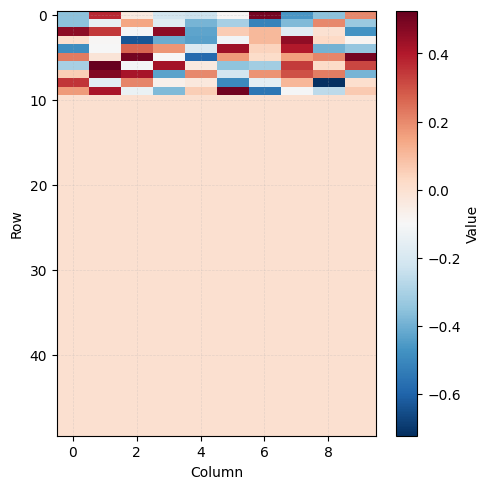

In [58]:

# Plot heatmap
plt.figure(figsize=(5, 5))
U_np = np.array(U)  # Convert JAX array to NumPy for plotting
im = plt.imshow(U_np, aspect='auto', cmap='RdBu_r', interpolation='nearest')
plt.colorbar(im, label='Value')
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

In [ ]:


def loss(qtilde):
    """Loss function: mean of absolute values of rotated u"""
    q, _ = jnp.linalg.qr(qtilde) 
    u_rotated = U @ q
    return jnp.mean(jnp.abs(u_rotated))


# Initialise Adam optimizer
key, subkey = jax.random.split(key)
qtilde = jax.random.normal(subkey, (k, k))
optimizer = optax.adam(learning_rate=0.004, eps=1e-4)
opt_state = optimizer.init(qtilde)


# Create value_and_grad function
loss_value_and_grad = jax.value_and_grad(loss)

# Optimization loop
for iteration in range(10000):
    loss_value, grads = loss_value_and_grad(qtilde)
    updates, opt_state = optimizer.update(grads, opt_state)
    qtilde = optax.apply_updates(qtilde, updates)
    
    if iteration % 1000 == 0:
        print(f"Iteration {iteration}, Loss: {float(loss_value)}")

# Get optimized q
q_opt,_ = jnp.linalg.qr(qtilde)

# output U @ q_opt


Iteration 0, Loss: 0.05080883204936981
Iteration 1000, Loss: 0.024526501074433327
Iteration 2000, Loss: 0.02203146368265152
Iteration 3000, Loss: 0.02127845399081707
Iteration 4000, Loss: 0.020124640315771103
Iteration 5000, Loss: 0.02005556784570217
Iteration 6000, Loss: 0.020075123757123947
Iteration 7000, Loss: 0.02006816305220127
Iteration 8000, Loss: 0.020052824169397354
Iteration 9000, Loss: 0.020082786679267883


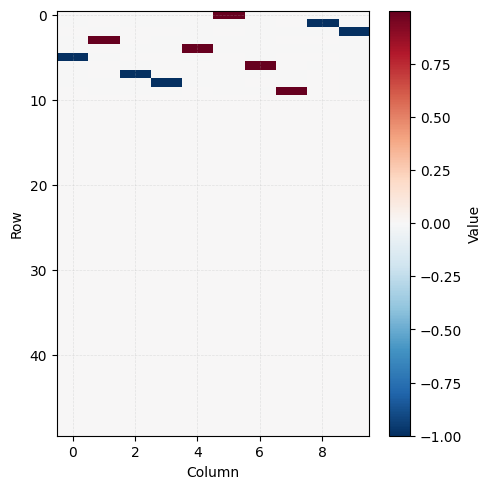

In [59]:
# Plot heatmap
plt.figure(figsize=(5, 5))
U_np = np.array(U @ q_opt)  # Convert JAX array to NumPy for plotting
im = plt.imshow(U_np, aspect='auto', cmap='RdBu_r', interpolation='nearest')
plt.colorbar(im, label='Value')
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()